# Optimizer dynamics you can see — original ARENA companion

**Question:** when do curvature, step size, momentum and noise turn convergence into oscillation or divergence?

You will draw the trajectory yourself, implement its updates, make a prediction before a reveal,
and find a counterexample to a tempting explanation. This is **analytic_toy** evidence on a
known 2-D positive-definite quadratic, not measured neural-network training.

**Learning objectives**

- Construct a rotated Hessian and explain its stiff and shallow directions.
- Implement unnormalized heavy-ball momentum and a reproducible simulation.
- Derive stability from characteristic roots, including the equality boundary.
- Use invariant and negative controls to distinguish geometry from plotting artifacts.
- Commit, test and revise an explanation on a held-out parameter regime.

Prerequisites: NumPy matrix multiplication, gradients, eigenvalues and the original
[ARENA 0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
Allow about 60–90 minutes; do exercises 1–4 first if time is short.
The external resource is Stanford's [Deep Learning Alchemy / CS 312](https://deep-learning-alchemy.github.io/).
Its source inventory is dated 2026-10-14 in the hub design; these original exercises do not
reproduce Stanford assignments or imply that tentative assignments have been released.

## Cold open: why can a larger gradient make a worse step?

Let $L(x)=\frac12 x^T Hx$, $H=\operatorname{diag}(1,9)$, $x_0=(1,0)$,
$v_0=0$, $\eta=0.1$, $\beta=0$. The gradient is $(1,0)$, so
$v_1=(1,0)$, **$x_1=(0.9,0)$ and $L(x_1)=0.405$**.
Start instead along the stiff axis: $(0,1)$ becomes $(0,0.1)$.
The same learning rate removes 90% of one coordinate and 10% of the other.
If $\eta=0.25$, that stiff coordinate becomes $-1.25$: crossing the valley increases loss.

We use float64 throughout and exactly the convention
$v_{t+1}=\beta v_t+Hx_t+\epsilon_t$, $x_{t+1}=x_t-\eta v_{t+1}$.
Noise is an independent seeded $N(0,\sigma^2 I)$ gradient perturbation each step.
There is **no $(1-\beta)$ multiplier**. Rotation is in degrees; curvature has units
gradient per coordinate, $\eta$ converts gradient to displacement, and $\beta$ is dimensionless.

In [1]:
import copy
import hashlib
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

# Local-only setup: no installs, downloads, models, accounts or GPU work.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'arena_ext').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})
print('CPU / NumPy float64; evidence_class = analytic_toy')

CPU / NumPy float64; evidence_class = analytic_toy


## Exercise 1 — build the landscape (★☆☆, 8 minutes)

Implement $H=R\,\mathrm{diag}(\lambda_{min},\lambda_{max})R^T$ with
$R=\begin{pmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{pmatrix}$.
Require $0<\lambda_{min}\leq\lambda_{max}$; do not rotate the eigenvalues themselves.
Before running the test, sketch which direction has tight contours at 90 degrees.

**Expected output:** two eigenvalues remain 1 and 9; at 90 degrees the diagonal is [9, 1].

<details><summary>Help / hint</summary>

Convert degrees to radians first. Matrix multiplication is @; elementwise multiplication gives the wrong landscape.

</details>

<details><summary>Solution</summary>

```python
def quadratic_hessian(lambda_min, lambda_max, rotation_deg=0.0):
    if not (0 < lambda_min <= lambda_max):
        raise ValueError('Need 0 < lambda_min <= lambda_max')
    angle = np.deg2rad(rotation_deg)
    R = np.array([[np.cos(angle), -np.sin(angle)],
                  [np.sin(angle), np.cos(angle)]], dtype=np.float64)
    return R @ np.diag([lambda_min, lambda_max]) @ R.T
```

</details>

In [2]:
def quadratic_hessian(lambda_min, lambda_max, rotation_deg=0.0):
    if not (0 < lambda_min <= lambda_max):
        raise ValueError('Need 0 < lambda_min <= lambda_max')
    angle = np.deg2rad(rotation_deg)
    R = np.array([[np.cos(angle), -np.sin(angle)],
                  [np.sin(angle), np.cos(angle)]], dtype=np.float64)
    return R @ np.diag([lambda_min, lambda_max]) @ R.T

In [3]:
H = quadratic_hessian(1.0, 9.0, 90.0)
np.testing.assert_allclose(H, np.diag([9., 1.]), atol=1e-14)
np.testing.assert_allclose(np.linalg.eigvalsh(quadratic_hessian(2., 7., 31.)), [2., 7.])
assert np.allclose(H, H.T), 'A Hessian must be symmetric.'
print('Exercise 1 passed: rotation preserves curvature, not axis labels.')

Exercise 1 passed: rotation preserves curvature, not axis labels.


## Exercise 2 — one heavy-ball step (★☆☆, 8 minutes)

Return `(x_next, v_next)` without mutating either input. Accept a supplied noise vector;
this keeps the random-number generator outside the update. Work out the second test by hand:
nonzero initial velocity exposes an accidental normalized-momentum implementation.

**Expected output:** the worked example and the nonzero-velocity case both pass.

<details><summary>Help / hint</summary>

Compute the new velocity in a new array. Position uses that velocity, not the previous one.

</details>

<details><summary>Solution</summary>

```python
def heavy_ball_step(x, v, H, eta, beta, noise):
    v_next = beta * np.asarray(v) + H @ np.asarray(x) + np.asarray(noise)
    x_next = np.asarray(x) - eta * v_next
    return x_next, v_next
```

</details>

In [4]:
def heavy_ball_step(x, v, H, eta, beta, noise):
    v_next = beta * np.asarray(v) + H @ np.asarray(x) + np.asarray(noise)
    x_next = np.asarray(x) - eta * v_next
    return x_next, v_next

In [5]:
x = np.array([1., 0.]); v = np.zeros(2)
x1, v1 = heavy_ball_step(x, v, np.diag([1., 9.]), .1, 0., np.zeros(2))
np.testing.assert_allclose(x1, [.9, 0.])
assert np.isclose(.5 * x1 @ np.diag([1., 9.]) @ x1, .405)
a, b = heavy_ball_step(np.array([1., -1.]), np.array([2., 1.]), np.diag([2., 3.]), .1, .5, np.array([.2, -.1]))
np.testing.assert_allclose(b, [3.2, -2.6])
np.testing.assert_allclose(a, [.68, -.74])
np.testing.assert_array_equal(x, [1., 0.]); np.testing.assert_array_equal(v, [0., 0.])
print('Exercise 2 passed: x1=(0.9,0), loss=0.405; momentum/noise and immutability checked.')

Exercise 2 passed: x1=(0.9,0), loss=0.405; momentum/noise and immutability checked.


### From one step to a trajectory

Record the initial state as row zero. A run of `steps=3` must contain four states and four losses.
The initial update norm is zero, because no update occurred yet. Stop before storing a nonfinite
or over-budget candidate, retaining the valid prefix and an explicit reason. A stopped curve is
not evidence of convergence. A magnitude limit is a safety guard, not a mathematical stability test.

## Exercise 3 — simulate, including honest stopping (★★☆, 15 minutes)

Implement the loop with `np.random.default_rng(seed)`, one two-component Gaussian draw
per step (even at sigma zero), and `v0=0`. Return arrays `states`, `losses`, `update_norms`
and a string `stop_reason`. Reject nonfinite candidates and states with norm exceeding `max_norm`.
Use `np.errstate` around candidate arithmetic so an unstable demonstration can stop cleanly.

**Expected output:** four stored states; unstable candidate beyond norm 10 stops after [1, -3, 9].

<details><summary>Help / hint</summary>

Draw noise inside the loop. Append only after checking the candidate; compare norms before changing x.

</details>

<details><summary>Solution</summary>

```python
def simulate_student(H, x0, eta, beta, steps, noise_std=0.0, seed=0, max_norm=1e6):
    x = np.array(x0, dtype=np.float64, copy=True)
    H = np.asarray(H, dtype=np.float64)
    if x.shape != (2,) or H.shape != (2, 2):
        raise ValueError('This lesson uses two-dimensional states.')
    if steps < 0 or noise_std < 0 or not 0 <= beta < 1 or eta < 0:
        raise ValueError('Invalid optimizer controls')
    v = np.zeros(2, dtype=np.float64)
    rng = np.random.default_rng(seed)
    states, losses, updates = [x.copy()], [float(.5 * x @ H @ x)], [0.0]
    reason = 'completed'
    for _ in range(steps):
        noise = rng.normal(0., noise_std, size=2)
        with np.errstate(over='ignore', invalid='ignore'):
            candidate, v_next = heavy_ball_step(x, v, H, eta, beta, noise)
            loss = float(.5 * candidate @ H @ candidate)
            norm = float(np.linalg.norm(candidate))
        if not np.all(np.isfinite(candidate)) or not np.isfinite(loss) or not np.isfinite(norm):
            reason = 'nonfinite'; break
        if norm > max_norm:
            reason = 'max_norm'; break
        updates.append(float(np.linalg.norm(candidate - x)))
        states.append(candidate.copy()); losses.append(loss)
        x, v = candidate, v_next
    return dict(states=np.array(states), losses=np.array(losses),
                update_norms=np.array(updates), stop_reason=reason)
```

</details>

In [6]:
def simulate_student(H, x0, eta, beta, steps, noise_std=0.0, seed=0, max_norm=1e6):
    x = np.array(x0, dtype=np.float64, copy=True)
    H = np.asarray(H, dtype=np.float64)
    if x.shape != (2,) or H.shape != (2, 2):
        raise ValueError('This lesson uses two-dimensional states.')
    if steps < 0 or noise_std < 0 or not 0 <= beta < 1 or eta < 0:
        raise ValueError('Invalid optimizer controls')
    v = np.zeros(2, dtype=np.float64)
    rng = np.random.default_rng(seed)
    states, losses, updates = [x.copy()], [float(.5 * x @ H @ x)], [0.0]
    reason = 'completed'
    for _ in range(steps):
        noise = rng.normal(0., noise_std, size=2)
        with np.errstate(over='ignore', invalid='ignore'):
            candidate, v_next = heavy_ball_step(x, v, H, eta, beta, noise)
            loss = float(.5 * candidate @ H @ candidate)
            norm = float(np.linalg.norm(candidate))
        if not np.all(np.isfinite(candidate)) or not np.isfinite(loss) or not np.isfinite(norm):
            reason = 'nonfinite'; break
        if norm > max_norm:
            reason = 'max_norm'; break
        updates.append(float(np.linalg.norm(candidate - x)))
        states.append(candidate.copy()); losses.append(loss)
        x, v = candidate, v_next
    return dict(states=np.array(states), losses=np.array(losses),
                update_norms=np.array(updates), stop_reason=reason)

In [7]:
run = simulate_student(np.diag([1., 9.]), [1., 0.], .1, 0., 3)
np.testing.assert_allclose(run['states'][:, 0], [.0+1., .9, .81, .729])
np.testing.assert_allclose(run['losses'], .5 * np.array([1., .9, .81, .729])**2)
np.testing.assert_allclose(run['update_norms'], [0., .1, .09, .081])
assert run['states'].shape == (4, 2) and run['stop_reason'] == 'completed'
short = simulate_student(np.eye(2), [1., 0.], 4., 0., 100, max_norm=10.)
assert short['stop_reason'] == 'max_norm' and len(short['states']) == 3
assert np.isfinite(short['losses']).all(), 'Never hide divergence behind clipped values.'
print('Exercise 3 passed: analytic trajectory and truncated unstable prefix checked.')

Exercise 3 passed: analytic trajectory and truncated unstable prefix checked.


## Predict before calculating stability

In one eigenvector direction, eliminate velocity to obtain
$x_{t+1}=(1+\beta-\eta\lambda)x_t-\beta x_{t-1}$.
Its characteristic polynomial is $r^2-(1+\beta-\eta\lambda)r+\beta$.
Both roots must be strictly inside the unit circle in **every** direction for
asymptotic convergence from all starts. For $0\leq\beta<1$, this gives
$0<\eta\lambda_{max}<2(1+\beta)$. At zero momentum this becomes
$0<\eta<2/\lambda_{max}$. Equality is a non-decaying oscillation, not convergence.
These are deterministic statements with fixed positive-definite H and zero noise.
A stable noisy run need not reach zero; loss need not decrease at every heavy-ball step.

## Exercise 4 — independent stability oracle (★★☆, 10 minutes)

Implement the largest absolute characteristic root across the two eigenvalues.
Use `np.roots`, not the simulator. Explain why an oracle derived from the recurrence can
catch a time-stepping bug even if a short trajectory happens to look plausible.

**Expected output:** rho=0.9, equality rho=1, and unchanged boundary loss 4.5.

<details><summary>Help / hint</summary>

The root magnitude, not its real part, determines decay. Complex conjugates can decay while oscillating.

</details>

<details><summary>Solution</summary>

```python
def stability_radius(lambda_min, lambda_max, eta, beta):
    return float(max(abs(root) for lam in (lambda_min, lambda_max)
                     for root in np.roots([1., -(1. + beta - eta * lam), beta])))
```

</details>

In [8]:
def stability_radius(lambda_min, lambda_max, eta, beta):
    return float(max(abs(root) for lam in (lambda_min, lambda_max)
                     for root in np.roots([1., -(1. + beta - eta * lam), beta])))

In [9]:
assert np.isclose(stability_radius(1., 9., .1, 0.), .9)
assert np.isclose(stability_radius(1., 9., 2/9, 0.), 1.)
assert stability_radius(1., 9., .3, 0.) > 1.
assert stability_radius(1., 9., .3, .5) < 1.
boundary = simulate_student(np.diag([1., 9.]), [0., 1.], 2/9, 0., 8)
np.testing.assert_allclose(boundary['losses'], np.full(9, 4.5))
print('Exercise 4 passed: strict boundary, unstable GD and stable heavy ball distinguished.')

Exercise 4 passed: strict boundary, unstable GD and stable heavy ball distinguished.


## Exercise 5 — rotate the whole experiment (★★☆, 8 minutes)

Return `(H_rotated, x0_rotated)` for an additional coordinate rotation.
Rotate the initial state as well as H. For deterministic runs the losses must agree, although
plotted coordinates change. With isotropic noise, distributions agree; rotating coordinates
without also rotating each realized noise vector does not give pathwise equality for a fixed seed.

**Expected output:** loss equality to float64 tolerance and a visible failure for the wrongly rotated control.

<details><summary>Help / hint</summary>

Use R @ H @ R.T and R @ x0. Isotropic noise is rotationally invariant in distribution, not under arbitrary same-seed coupling.

</details>

<details><summary>Solution</summary>

```python
def rotate_experiment(H, x0, rotation_deg):
    angle = np.deg2rad(rotation_deg)
    R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    return R @ H @ R.T, R @ np.asarray(x0)
```

</details>

In [10]:
def rotate_experiment(H, x0, rotation_deg):
    angle = np.deg2rad(rotation_deg)
    R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    return R @ H @ R.T, R @ np.asarray(x0)

In [11]:
H = np.diag([1., 9.]); x0 = np.array([1., .5])
Hr, xr = rotate_experiment(H, x0, 37.)
a = simulate_student(H, x0, .12, .4, 40)
b = simulate_student(Hr, xr, .12, .4, 40)
np.testing.assert_allclose(a['losses'], b['losses'], atol=1e-13)
wrong = simulate_student(Hr, x0, .12, .4, 40)
assert not np.allclose(a['losses'], wrong['losses']), 'This control should expose a partly rotated experiment.'
n1 = simulate_student(H, x0, .12, .4, 40, noise_std=.2, seed=12)
n2 = simulate_student(H, x0, .12, .4, 40, noise_std=.2, seed=12)
np.testing.assert_array_equal(n1['states'], n2['states'])
print('Exercise 5 passed: rotation invariant; missing state rotation fails; seeded noise replays.')

Exercise 5 passed: rotation invariant; missing state rotation fails; seeded noise replays.


## Signature result: one landscape, three explanations

The following figure is computed from your functions. The left panel shows paths over contours;
the middle panel tests decay against controls; the right panel shows displacement per update.
**Assumptions:** fixed positive-definite H, unnormalized heavy ball, float64 CPU,
independent isotropic Gaussian gradient noise only where labeled. Curves include step zero.
Zero losses are masked on the log axis and counted in the label, never replaced by an arbitrary epsilon.
The unstable run stops at the stated magnitude guard and is drawn to its last valid point.
The root oracle speaks about all initial states; this finite picture is one initial state.

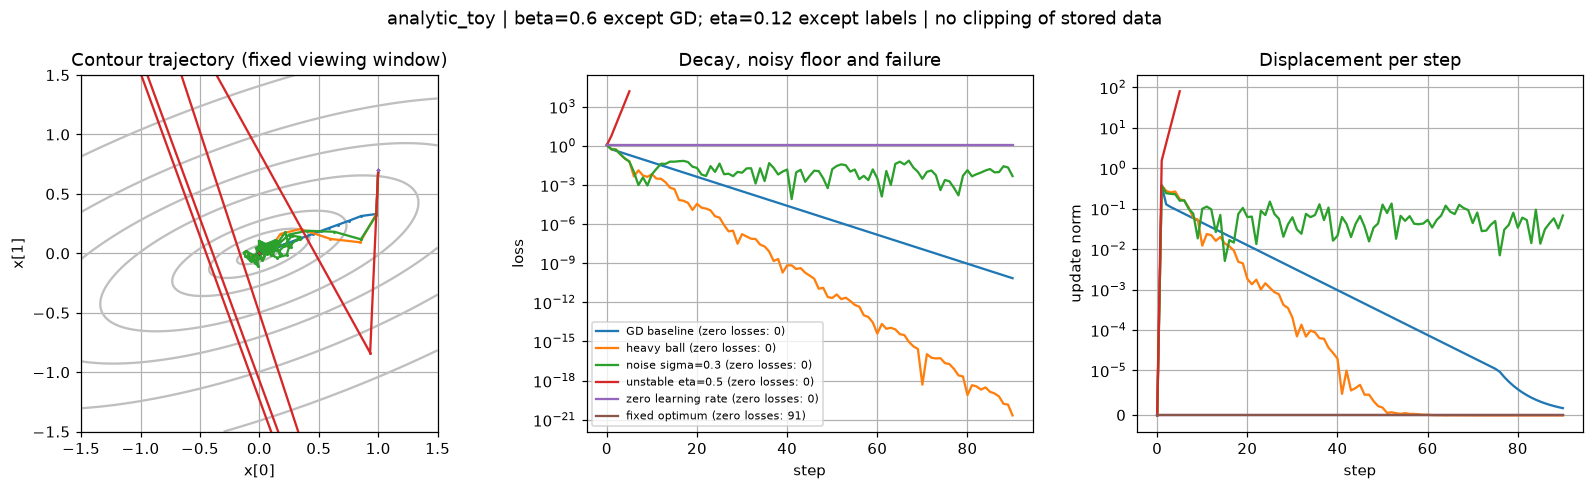

Unstable stop: max_norm | retained steps: 5


In [12]:
H = quadratic_hessian(1., 9., 20.)
start = np.array([1., .7])
runs = {
    'GD baseline': simulate_student(H, start, .12, 0., 90),
    'heavy ball': simulate_student(H, start, .12, .6, 90),
    'noise sigma=0.3': simulate_student(H, start, .12, .6, 90, .3, 7),
    'unstable eta=0.5': simulate_student(H, start, .5, .6, 90, max_norm=100.),
    'zero learning rate': simulate_student(H, start, 0., .6, 90),
    'fixed optimum': simulate_student(H, [0., 0.], .12, .6, 90),
}
signature_figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
grid = np.linspace(-1.5, 1.5, 160)
xx, yy = np.meshgrid(grid, grid)
points = np.stack([xx, yy], axis=-1)
zz = .5 * np.einsum('...i,ij,...j->...', points, H, points)
axes[0].contour(xx, yy, zz, levels=[.02, .1, .3, 1., 2., 4., 8.], colors='0.75')
for name, run in runs.items():
    state = run['states']; steps = np.arange(len(state))
    zeros = int(np.count_nonzero(run['losses'] == 0))
    axes[0].plot(*state.T, '.-', markersize=2, label=name)
    positive = np.ma.masked_less_equal(run['losses'], 0.)
    axes[1].plot(steps, positive, label=f'{name} (zero losses: {zeros})')
    axes[2].plot(steps, run['update_norms'], label=name)
axes[0].set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), xlabel='x[0]', ylabel='x[1]', title='Contour trajectory (fixed viewing window)')
axes[0].set_aspect('equal')
axes[1].set(yscale='log', xlabel='step', ylabel='loss', title='Decay, noisy floor and failure')
axes[2].set_yscale('symlog', linthresh=1e-5)
axes[2].set(xlabel='step', ylabel='update norm', title='Displacement per step')
axes[1].legend(fontsize=7)
signature_figure.suptitle('analytic_toy | beta=0.6 except GD; eta=0.12 except labels | no clipping of stored data')
signature_figure.tight_layout()
display(signature_figure)
plt.close(signature_figure)
print('Unstable stop:', runs['unstable eta=0.5']['stop_reason'],
      '| retained steps:', len(runs['unstable eta=0.5']['states']) - 1)

In [13]:
Hr, xr = rotate_experiment(H, start, 43.)
rotated = simulate_student(Hr, xr, .12, .6, 90)
replay = simulate_student(H, start, .12, .6, 90, .3, 7)
controls = {
    'zero learning rate': np.all(runs['zero learning rate']['states'] == start),
    'fixed optimum': np.all(runs['fixed optimum']['losses'] == 0),
    'rotation': np.allclose(rotated['losses'], runs['heavy ball']['losses']),
    'noise reproducibility': np.array_equal(replay['states'], runs['noise sigma=0.3']['states']),
    'unstable step': runs['unstable eta=0.5']['stop_reason'] == 'max_norm',
}
assert all(controls.values()), controls
for name, passed in controls.items():
    print(f'{name}: {"passed" if passed else "FAILED"}')
print('Final noisy loss:', runs['noise sigma=0.3']['losses'][-1])

zero learning rate: passed
fixed optimum: passed
rotation: passed
noise reproducibility: passed
unstable step: passed
Final noisy loss: 0.004762194195157257


### Read the picture

Momentum can cross a contour uphill for several steps while its envelope shrinks. Compare its loss
and update curves before calling an oscillation unstable. The zero-learning-rate line is a baseline
for doing nothing; the fixed optimum tests whether the code injects motion without noise.
The noisy curve resists the claim that deterministic stability guarantees exact convergence to zero.
The contour panel uses a fixed viewing window so it can show the useful valley detail; unstable
points outside that window still appear unmodified in the loss/update panels and stored arrays.

**Falsify your explanation:** “if the spectral radius is above one, every trajectory diverges.”
Find a start with no component in the unstable eigendirection. Predict its behavior first,
then add a tiny component in that direction. How long does the apparent counterexample survive?

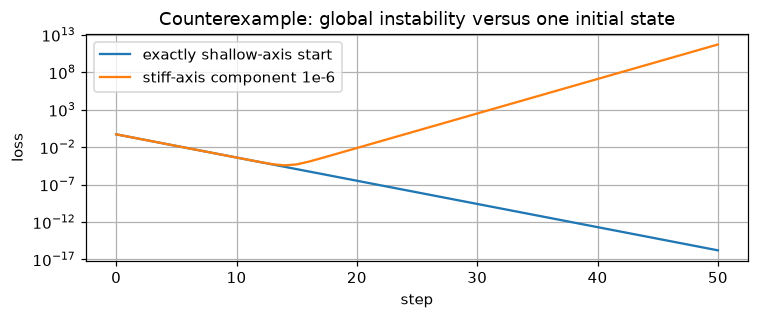

In [14]:
# A deliberately falsifiable claim: all starts diverge above the global GD boundary.
H_counter = np.diag([1., 9.])
aligned = simulate_student(H_counter, [1., 0.], .3, 0., 50)
perturbed = simulate_student(H_counter, [1., 1e-6], .3, 0., 50)
assert stability_radius(1., 9., .3, 0.) > 1.
assert aligned['losses'][-1] < aligned['losses'][0]
assert perturbed['losses'][-1] > perturbed['losses'][0]
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(aligned['losses'], label='exactly shallow-axis start')
ax.semilogy(perturbed['losses'], label='stiff-axis component 1e-6')
ax.set(xlabel='step', ylabel='loss', title='Counterexample: global instability versus one initial state')
ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)

## Try It Yourself — change one cause

Before running: write down which axis will overshoot and whether the envelope should decay.
Change one of the controls below, keeping the rest fixed. Run it, then reset to baseline before
changing another. The seed fixes a noise realization; changing the seed is a new experiment.
Try doubling both curvatures and halving eta: deterministic paths should agree step for step.
For noise, decide whether its gradient scale should also change to preserve that invariance.

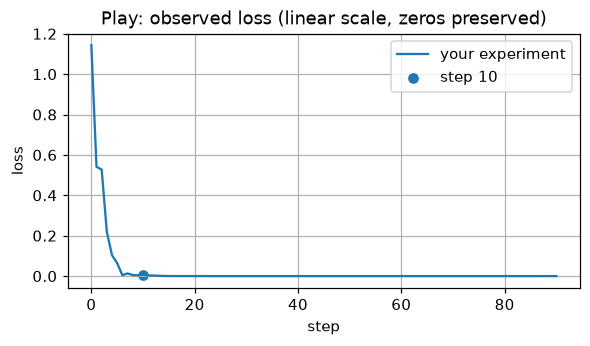

Selected state: [-0.08702 -0.00319] | stop: completed


In [15]:
# Reset-to-baseline values; edit one cause at a time. This cell launches CPU arithmetic only.
play = dict(lambda_min=1., lambda_max=9., rotation_deg=20., eta=.12,
            beta=.6, noise_std=0., seed=7, steps=90, x0=[1., .7])
play_H = quadratic_hessian(play['lambda_min'], play['lambda_max'], play['rotation_deg'])
play_run = simulate_student(play_H, play['x0'], play['eta'], play['beta'],
                            play['steps'], play['noise_std'], play['seed'])
# Select a step, rerun to inspect that state, or reset to the dictionary above.
selected_step = min(10, len(play_run['states']) - 1)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(play_run['losses'], label='your experiment')
ax.scatter([selected_step], [play_run['losses'][selected_step]], label=f'step {selected_step}')
ax.set(xlabel='step', ylabel='loss', title='Play: observed loss (linear scale, zeros preserved)')
ax.legend(); display(fig); plt.close(fig)
print('Selected state:', play_run['states'][selected_step], '| stop:', play_run['stop_reason'])

### Record plumbing: keep the notebook and app scientifically identical

The following adapter maps our teaching name `rotation_deg` to the reference name `angle_deg`.
It includes every scientific input, explicit noise/seed defaults and the simulator version.
Shared validation and immutable prediction transitions provide interoperability; they do not
calculate the optimizer trajectory. Exposure stays in this live kernel after reveal; a fresh
kernel is not a tamper-proof record of prior exposure. Mark previously viewed cases as practice.

In [16]:
from dataclasses import asdict
from arena_ext.mastery.quadratic import QuadraticConfig, SIMULATOR_VERSION
from arena_ext.mastery.challenges import (new_attempt, commit_prediction as commit_shared,
    reveal as reveal_shared, expose_case)
from arena_ext.mastery.records import (fingerprint, validate_record, loads_attempt,
    export_attempt, replay)

if 'notebook_exposed_cases' not in globals():
    notebook_exposed_cases = []
# The supplied solution is a worked demonstration, not unseen learner evidence.
WORKED_DEMONSTRATION = True

def scientific_config(config):
    allowed = {'lambda_min', 'lambda_max', 'rotation_deg', 'x0', 'eta', 'beta',
               'steps', 'noise_std', 'seed'}
    if set(config) - allowed:
        raise ValueError('Unknown scientific settings cannot be silently dropped')
    reference_config = QuadraticConfig(
        lambda_min=config['lambda_min'], lambda_max=config['lambda_max'],
        angle_deg=config['rotation_deg'], x0=tuple(config['x0']),
        eta=config['eta'], beta=config['beta'], steps=config['steps'],
        noise_std=config.get('noise_std', 0.), seed=config.get('seed', 0))
    result = asdict(reference_config)
    result['x0'] = list(result['x0'])
    result['simulator_version'] = SIMULATOR_VERSION
    return result

## Exercise 6 — commit an unseen prediction (★★☆, 8 minutes)

Implement `commit_prediction` so it takes a deep snapshot of the question configuration,
stores a strict canonical JSON fingerprint, and rejects missing predictions, invalid confidence
or empty reasoning. `reveal_prediction` must reject any changed configuration before simulating.
The configuration below is held out from the earlier exploration: do not run it until you commit.
This is local self-study, not tamper-proof assessment. A configuration you already inspected is
practice, never unseen evidence. The result is a schema-1 record accepted by the app's JSON importer and replay.
The full configuration, reasoning and outcomes appear in the saved cell output.
Local export is opt-in: after reveal, call `export_notebook_record(chosen_directory)`.
Running all cells does not write a progress file. Shared record plumbing is allowed here;
the optimizer method above remains your own code.

**Expected output:** changed settings cannot reveal, and revealing returns a new attempt without modifying the commitment.

<details><summary>Help / hint</summary>

Use the shared immutable challenge transitions, but compute the observed outcome with your stability oracle and simulator. Fingerprint every scientific setting using the schema bridge below.

</details>

<details><summary>Solution</summary>

```python
def commit_prediction(config, prediction, confidence, reasoning):
    if prediction not in {'converges', 'does not converge'}:
        raise ValueError('Commit a directional prediction first')
    scientific = scientific_config(config)
    if scientific['noise_std'] != 0:
        raise ValueError('This all-start convergence challenge assumes zero noise')
    pending = new_attempt('notebook-heldout-optimization', fingerprint(scientific),
                          exposed_cases=notebook_exposed_cases)
    return commit_shared(pending, prediction == 'converges', confidence, reasoning)

def reveal_prediction(attempt, config):
    scientific = scientific_config(config)
    config_hash = fingerprint(scientific)
    if config_hash != attempt['config_fingerprint'] or attempt['status'] != 'committed':
        raise ValueError('Commit unchanged settings before revealing; retain revealed records')
    H = quadratic_hessian(scientific['lambda_min'], scientific['lambda_max'], scientific['angle_deg'])
    run = simulate_student(H, scientific['x0'], scientific['eta'], scientific['beta'],
                           scientific['steps'], scientific['noise_std'], scientific['seed'])
    rho = stability_radius(scientific['lambda_min'], scientific['lambda_max'],
                           scientific['eta'], scientific['beta'])
    revealed = reveal_shared(attempt, config_hash, bool(rho < 1))
    return revealed, run
```

</details>

In [17]:
def commit_prediction(config, prediction, confidence, reasoning):
    if prediction not in {'converges', 'does not converge'}:
        raise ValueError('Commit a directional prediction first')
    scientific = scientific_config(config)
    if scientific['noise_std'] != 0:
        raise ValueError('This all-start convergence challenge assumes zero noise')
    pending = new_attempt('notebook-heldout-optimization', fingerprint(scientific),
                          exposed_cases=notebook_exposed_cases)
    return commit_shared(pending, prediction == 'converges', confidence, reasoning)

def reveal_prediction(attempt, config):
    scientific = scientific_config(config)
    config_hash = fingerprint(scientific)
    if config_hash != attempt['config_fingerprint'] or attempt['status'] != 'committed':
        raise ValueError('Commit unchanged settings before revealing; retain revealed records')
    H = quadratic_hessian(scientific['lambda_min'], scientific['lambda_max'], scientific['angle_deg'])
    run = simulate_student(H, scientific['x0'], scientific['eta'], scientific['beta'],
                           scientific['steps'], scientific['noise_std'], scientific['seed'])
    rho = stability_radius(scientific['lambda_min'], scientific['lambda_max'],
                           scientific['eta'], scientific['beta'])
    revealed = reveal_shared(attempt, config_hash, bool(rho < 1))
    return revealed, run

In [18]:
fixture = dict(lambda_min=1., lambda_max=2., rotation_deg=0., eta=.1, beta=0., steps=4, x0=[1., 1.])
record = commit_prediction(fixture, 'converges', .7, 'Both contraction factors are inside the unit circle.')
original = copy.deepcopy(record)
fixture['eta'] = .9
try:
    reveal_prediction(record, fixture)
except ValueError:
    pass
else:
    raise AssertionError('Changed question was revealed against an old prediction')
assert record == original, 'Shared transitions must not mutate committed predictions.'
fixture['eta'] = .1
revealed_fixture, _ = reveal_prediction(record, fixture)
assert record['status'] == 'committed' and revealed_fixture['status'] == 'revealed'
for prediction, confidence, reason in [(None, .5, 'test'), ('converges', 1.1, 'test'), ('converges', .5, '')]:
    try:
        commit_prediction(fixture, prediction, confidence, reason)
    except ValueError:
        pass
    else:
        raise AssertionError('An incomplete prediction was accepted')
print('Exercise 6 passed: immutable commitment, prediction validation and stale reveal guard checked.')

Exercise 6 passed: immutable commitment, prediction validation and stale reveal guard checked.


### Held-out transfer — stop here and commit

For the unseen case below, predict whether deterministic heavy ball converges from every initial
state and give your confidence and causal explanation. The rotation, curvature ratio, step size and
momentum differ from the baseline. Do the root reasoning on paper before executing the reveal.
In the solution notebook the sample commitment is an **illustrative worked answer**;
it is not a measurement of anyone's independent learning or calibration.

In [19]:
heldout_config = dict(lambda_min=.7, lambda_max=6., rotation_deg=57.,
                      eta=.39, beta=.35, steps=100, x0=[-.8, 1.1], noise_std=0., seed=17)
# Already seen this case? Set this True before committing; it stays practice.
previously_seen = WORKED_DEMONSTRATION
if previously_seen:
    notebook_exposed_cases = expose_case(notebook_exposed_cases, 'notebook-heldout-optimization',
                                         fingerprint(scientific_config(heldout_config)))

In [20]:
heldout_attempt = commit_prediction(
    heldout_config, 'converges', .7,
    'The largest eta*lambda is 2.34, below 2*(1+beta)=2.7; both modes should decay.')
print('Committed prediction:', heldout_attempt['prediction'], '| confidence:', heldout_attempt['confidence'])

Committed prediction: True | confidence: 0.7


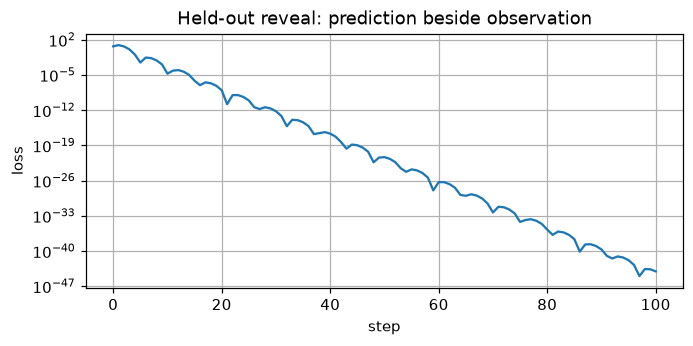

Prediction: True | observed all-start stability: True
PORTABLE_RECORD_JSON_BEGIN
{
  "attempt": {
    "assessment": "practice",
    "attempt_id": "625675e6397e42f0962f470a8572cbc4",
    "challenge_id": "notebook-heldout-optimization",
    "confidence": 0.7,
    "config_fingerprint": "b858ddb196d98659f6931cd4892e571441220306a0e4c8a90ec91399e61b50db",
    "observed": true,
    "prediction": true,
    "reasoning": "The largest eta*lambda is 2.34, below 2*(1+beta)=2.7; both modes should decay.",
    "score": 0.09000000000000002,
    "score_type": "brier",
    "status": "revealed"
  },
  "attempt_id": "625675e6397e42f0962f470a8572cbc4",
  "challenge_id": "notebook-heldout-optimization",
  "code_revision": "executed-notebook-inputs-sha256:29935994e51b494cdf28a8a07a1b7ef21d2842bdbe9f9e792814cdbee4dea17c",
  "config": {
    "angle_deg": 57.0,
    "beta": 0.35,
    "eta": 0.39,
    "lambda_max": 6.0,
    "lambda_min": 0.7,
    "noise_std": 0.0,
    "seed": 17,
    "simulator_version": "quadrati

In [21]:
heldout_attempt, heldout_run = reveal_prediction(heldout_attempt, heldout_config)
notebook_exposed_cases = expose_case(notebook_exposed_cases, heldout_attempt['challenge_id'],
                                     heldout_attempt['config_fingerprint'])
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(heldout_run['losses'])
ax.set(xlabel='step', ylabel='loss', title='Held-out reveal: prediction beside observation')
display(fig); plt.close(fig)
print('Prediction:', heldout_attempt['prediction'], '| observed all-start stability:', heldout_attempt['observed'])
scientific = scientific_config(heldout_config)
# Hash actual executed inputs (including student edits) when running in Jupyter.
shell = get_ipython()
executed_inputs = shell.history_manager.input_hist_raw if shell is not None else globals().get('__executed_sources__', [])
if not executed_inputs:
    raise ValueError('Exact executed-source provenance is required for a portable record')
code_hash = hashlib.sha256(json.dumps(executed_inputs, ensure_ascii=False).encode()).hexdigest()
lesson_hash = hashlib.sha256((ROOT / 'mastery_hub/units/u02_optimization/lesson.py').read_bytes()).hexdigest()
# These controls were actually calculated above, not copied from a historical report.
control_outcomes = {name: {'passed': bool(passed)} for name, passed in controls.items()}
control_outcomes['heldout_observation'] = {
    'spectral_radius': stability_radius(scientific['lambda_min'], scientific['lambda_max'],
                                       scientific['eta'], scientific['beta']),
    'initial_loss': float(heldout_run['losses'][0]),
    'final_loss': float(heldout_run['losses'][-1]),
    'stop_reason': heldout_run['stop_reason'],
    'steps_completed': len(heldout_run['states']) - 1}
portable_record = validate_record(dict(
    schema_version=1, unit_id='u02_optimization',
    challenge_id=heldout_attempt['challenge_id'], attempt_id=heldout_attempt['attempt_id'],
    config=scientific, config_fingerprint=fingerprint(scientific),
    source_revision='lesson.py-sha256:' + lesson_hash,
    code_revision='executed-notebook-inputs-sha256:' + code_hash,
    seeds=[scientific['seed']], evidence_class='analytic_toy', attempt=heldout_attempt,
    control_outcomes=control_outcomes, next_action='', reflection=''))
# Assert exact replay compatibility before offering export. This does not replace your method.
replayed_trace = replay(portable_record)
np.testing.assert_allclose(replayed_trace.states, heldout_run['states'], atol=1e-13)
np.testing.assert_allclose(replayed_trace.losses, heldout_run['losses'], atol=1e-13)
np.testing.assert_allclose(replayed_trace.update_norms, heldout_run['update_norms'], atol=1e-13)
print('PORTABLE_RECORD_JSON_BEGIN')
print(json.dumps(portable_record, sort_keys=True, indent=2, allow_nan=False))
print('PORTABLE_RECORD_JSON_END')

def export_notebook_record(chosen_directory):
    # Only an explicit function call writes a private local JSON file; never called by Run All.
    return export_attempt(portable_record, Path(chosen_directory))

## Independent reference comparison

The taught method above is your implementation. Only now import the package reference to check
it on a new ordinary deterministic configuration. Agreement between implementations is a useful
engineering check; the hand-computed cases and characteristic-root derivation provide independent
mathematical evidence. No reference plot or precomputed report supplies the signature figure.

In [22]:
from arena_ext.mastery.quadratic import QuadraticConfig, simulate
reference_config = QuadraticConfig(lambda_min=.8, lambda_max=4., angle_deg=23.,
                                   eta=.07, beta=.4, steps=13, x0=(.3, -.7),
                                   noise_std=0., seed=0)
reference = simulate(reference_config)
own = simulate_student(quadratic_hessian(.8, 4., 23.), [.3, -.7], .07, .4, 13)
np.testing.assert_allclose(own['states'], reference.states, atol=1e-13)
np.testing.assert_allclose(own['losses'], reference.losses, atol=1e-13)
np.testing.assert_allclose(own['update_norms'], reference.update_norms, atol=1e-13)
print('Independent package parity: states, losses and update norms agree.')

Independent package parity: states, losses and update norms agree.


## Reflection and next experiment

1. Which prediction surprised you? Quote the setting and the sign of the mismatch.
2. Explain why increasing momentum can stabilize one learning rate while making individual
   steps increase loss. Which of your plots supports each part?
3. Give a falsification: name one condition under which your current explanation fails.
   Use the shallow-axis counterexample or nonzero noise rather than saying “real life differs”.
4. Save one next action: a configuration you have not revealed and a directional prediction.
   Return later and commit before running it; do not relabel a replay as unseen.

**Transfer to research:** in a neural network, the local Hessian changes along a trajectory,
gradients are minibatch estimates, symmetry can introduce zero eigenvalues and momentum
conventions differ across optimizers. A projected 2-D trajectory can conceal unstable
directions. A real-model follow-up would freeze the model, data split, seeds, optimizer
convention, budget and held-out condition before comparing results. This notebook runs
no model and supports no transformer, VLM, scaling-law or optimizer-superiority claim.
For interpretability, ask whether a visually smooth projected residual trajectory reflects
its true high-dimensional dynamics or just the chosen coordinates.

**Limitations:** the loss is globally quadratic and positive definite; noise is isotropic and
independent, not data-dependent; stability is asymptotic and does not promise monotone loss
or fast convergence. Same-seed comparisons are paired experiments, not independent samples.
A few self-study predictions do not establish calibration or mastery. Human walkthrough
acceptance remains separate from executing this notebook successfully.

**Reading and anomaly hunting:** revisit original ARENA 0.3 for optimizer implementations;
[Why Momentum Really Works](https://distill.pub/2017/momentum/) develops the eigendirection
intuition; follow [Stanford CS 312](https://deep-learning-alchemy.github.io/) upstream for its
original material. Try a nearly flat direction and explain why stable can still be too slow.
These links are further reading, not copied assignment content or fresh empirical evidence.